<a href="https://colab.research.google.com/github/manisha8088/ml-lab/blob/main/aimllab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

    Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result
0    18         2.5        75.0           55.0               60   Pass
1    19         5.0        82.0           68.0               90   Pass
2    18        68.0        55.0           61.0               75   Pass
3    20         2.0        91.0           90.0               85   Pass
4    19         5.0        88.0           78.0               70   Pass
5    18         1.5         NaN           45.0               77   Fail
6    21         7.0         NaN           92.0               89   Pass
7    20         4.5         NaN           72.0               89   Pass
8    20         4.5        80.0           72.0               77   Pass
9    18         3.0        64.0            NaN               88   Fail
10   19         5.0        82.0           68.0               90   Pass
11   18        68.0        55.0           61.0               75   Pass
   Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result
0   18 

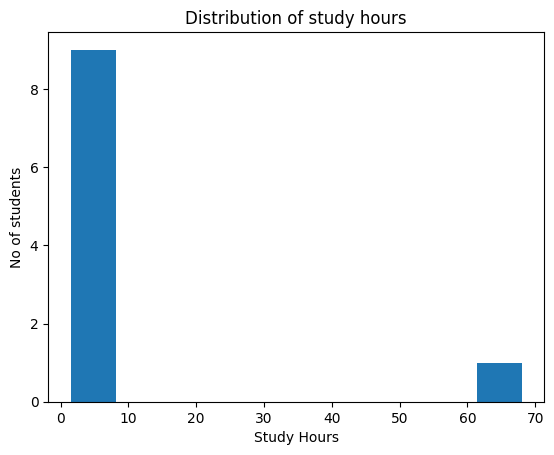

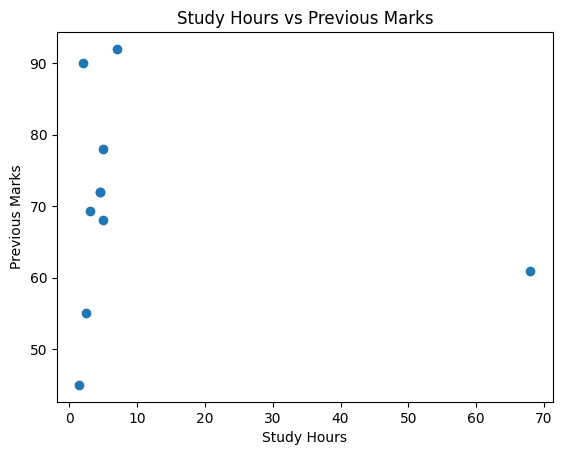

0    62.500000
1    78.800000
2    63.400000
3    88.800000
4    78.600000
5    63.500000
6    85.900000
7    77.900000
8    75.900000
9    73.309091
Name: PerformanceScore, dtype: float64
   Age  StudyHours  Attendance  ...  AssignmentScore  Result PerformanceScore
0   18         2.5        75.0  ...               60    Pass             62.5
1   19         5.0        82.0  ...               90    Pass             78.8
2   18        68.0        55.0  ...               75    Pass             63.4
3   20         2.0        91.0  ...               85    Pass             88.8
4   19         5.0        88.0  ...               70    Pass             78.6

[5 rows x 7 columns]
0    1
1    1
2    1
3    1
4    1
5    0
6    1
7    1
8    1
9    0
Name: Result, dtype: int64
(8, 5)
(2, 5)
[1 1]
   Actual  Predicted
8       1          1
1       1          1
accuracy: 1.0
precision: 1.0
recall: 1.0
f1 score: 1.0
classification report:
               precision    recall  f1-score   support

       

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


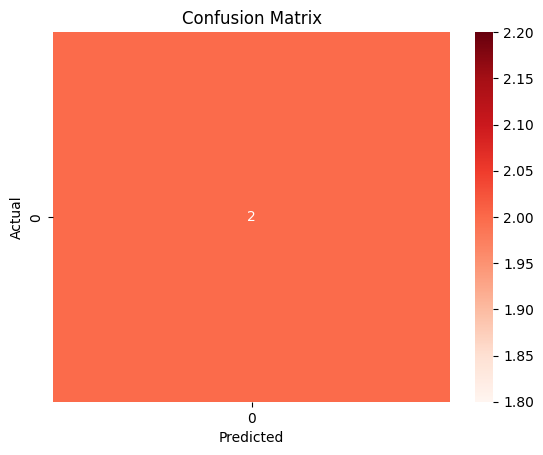

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report

data=pd.read_csv('aiml.csv')
#pd.read_excel("file.xlsx").to_csv("file.csv", index=False)
print(data)
print(data.head())
print(data.shape)
print(data.columns)
print(data.dtypes)
print(data.info())
print(data.describe())
print(data.isnull().sum())  #check missing
print(data.duplicated().sum()) #check duplicate

#step 4,data cleaning

data['StudyHours']=data['StudyHours'].fillna(data['StudyHours'].mean())
data['Attendance']=data['Attendance'].fillna(data['Attendance'].mean())
data['PreviousMarks']=data['PreviousMarks'].fillna(data['PreviousMarks'].mean())
print(data.isnull().sum())

data=data.drop_duplicates()
print(data.duplicated().sum())

plt.hist(data['StudyHours'])
plt.xlabel('Study Hours')
plt.ylabel('No of students')
plt.title('Distribution of study hours')
plt.show()

plt.scatter(data['StudyHours'],data['PreviousMarks'])
plt.xlabel('Study Hours')
plt.ylabel('Previous Marks')
plt.title('Study Hours vs Previous Marks')
plt.show()

#step 7,feature engineering

data['PerformanceScore']=(0.4*data['PreviousMarks']+0.3*data['Attendance']+0.3*data['AssignmentScore'])
print(data['PerformanceScore'])
print(data.head())

#step 8,separate features and target

X=data[["StudyHours","Attendance","PreviousMarks","AssignmentScore","PerformanceScore"]]
y=data["Result"]

#step 9

y=y.map({'Pass':1,'Fail':0})
print(y)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)

#ml algo

model=DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
    class_weight='balanced'

    )
model.fit(X_train,y_train)

y_pred=model.predict(X_test)
print(y_pred)
result=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(result)
accuracy=accuracy_score(y_test,y_pred)
print("accuracy:",accuracy)
precision=precision_score(y_test,y_pred)
print("precision:",precision)
recall=recall_score(y_test,y_pred)
print("recall:",recall)
#recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)
print("f1 score:",f1)
classification_report=classification_report(y_test,y_pred)
print("classification report:\n",classification_report)
cm=confusion_matrix(y_test,y_pred)
print("confusion matrix:\n",cm)
sns.heatmap(cm,annot=True,fmt='d',cmap='Reds')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
